# New Cereal Launch: Market Map & Consumer Segmentation

**Business question:** a cereal manufacturer wants to launch a new product. *Where is the gap in a crowded market, and which consumers would buy a product built to fill it?*

**Approach**
1. **Market map (PCA):** reduce 9 nutrition attributes of 74 existing cereals to 2 dimensions and look for empty space.
2. **Consumer segments (K-means):** cluster 800 survey respondents on 20 attitude questions, choose K with evidence, and profile each segment.
3. **Recommendation:** match the market gap to the segment that wants it, and size the opportunity.

*Originally completed in RapidMiner for NYU MASY 1215 (Data-Driven Decision Making); rebuilt and extended in Python.*

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

SEED = 42
FIG = "figures/"

# Chart style: thin marks, recessive axes, validated categorical palette
SURFACE, INK, INK2, GRID, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#b5b4ae"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed order, never cycled
DIVERGING = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

## Part 1 · Market map (PCA)

**Data:** the public *80 Cereals* dataset: nutrition facts per serving for 77 US breakfast cereals.

In [2]:
cereal = pd.read_excel("data/cereal_nutrition.xlsx", sheet_name="cereal")
NUTRIENTS = ["calories", "protein", "fat", "sodium", "fiber", "carbo", "sugars", "potass", "vitamins"]

# The dataset codes missing values as -1
missing = cereal[(cereal[NUTRIENTS] == -1).any(axis=1)]
print("Cereals with missing values (dropped):", ", ".join(missing["name"]))
cereal = cereal[~cereal.index.isin(missing.index)].reset_index(drop=True)
print("Cereals analysed:", len(cereal))
cereal[NUTRIENTS].describe().round(1)

Cereals with missing values (dropped): Almond Delight, Cream of Wheat (Quick), Quaker Oatmeal
Cereals analysed: 74


,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins
count,74.0,74.0,74.0,74.0,74.0,74.0,74.0,74.0,74.0
mean,107.0,2.5,1.0,162.4,2.2,14.7,7.1,98.5,29.1
std,19.8,1.1,1.0,82.8,2.4,3.9,4.4,70.9,22.3
min,50.0,1.0,0.0,0.0,0.0,5.0,0.0,15.0,0.0
25%,100.0,2.0,0.0,135.0,0.2,12.0,3.0,41.2,25.0
50%,110.0,2.5,1.0,180.0,2.0,14.5,7.0,90.0,25.0
75%,110.0,3.0,1.0,217.5,3.0,17.0,11.0,120.0,25.0
max,160.0,6.0,5.0,320.0,14.0,23.0,15.0,330.0,100.0


Nutrients are on very different scales (sodium in mg, protein in g), so each is standardized before PCA. Otherwise sodium and potassium would dominate purely because of their units.

PC1 explains 29.5%, PC2 22.7%; together 52.2% of the variance


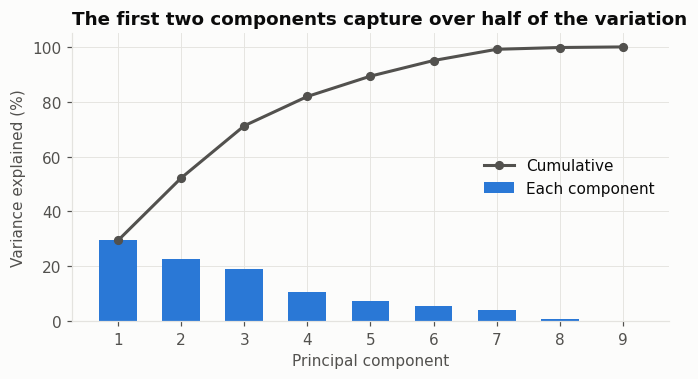

In [3]:
X_cereal = StandardScaler().fit_transform(cereal[NUTRIENTS])
pca = PCA(random_state=SEED).fit(X_cereal)
evr = pca.explained_variance_ratio_

# Orient components so the positive end is easy to read
comps = pca.components_.copy()
if comps[0, NUTRIENTS.index("fiber")] < 0:  comps[0] *= -1
if comps[1, NUTRIENTS.index("sugars")] < 0: comps[1] *= -1
scores = X_cereal @ comps[:2].T
cereal["PC1"], cereal["PC2"] = scores[:, 0], scores[:, 1]

print(f"PC1 explains {evr[0]:.1%}, PC2 {evr[1]:.1%}; together {evr[:2].sum():.1%} of the variance")

fig, ax = plt.subplots(figsize=(7, 3.4))
k = np.arange(1, len(evr) + 1)
ax.bar(k, evr * 100, color=SERIES[0], width=0.6, label="Each component")
ax.plot(k, np.cumsum(evr) * 100, color=INK2, lw=2, marker="o", ms=5, label="Cumulative")
ax.set_xticks(k); ax.set_xlabel("Principal component"); ax.set_ylabel("Variance explained (%)")
ax.set_ylim(0, 105); ax.legend(frameon=False, loc="center right")
ax.set_title("The first two components capture over half of the variation")
fig.savefig(FIG + "pca_scree.png"); plt.show()

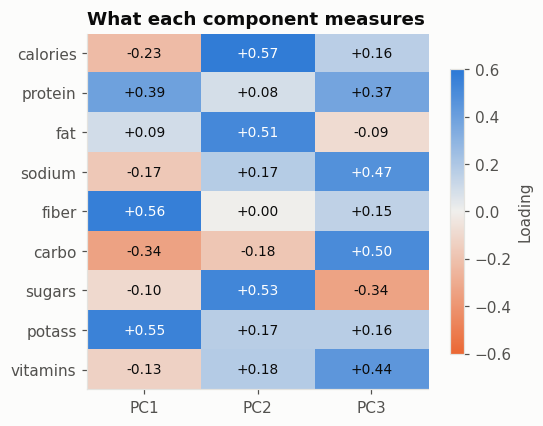

,PC1,PC2,PC3
calories,-0.23,0.57,0.16
protein,0.39,0.08,0.37
fat,0.09,0.51,-0.09
sodium,-0.17,0.17,0.47
fiber,0.56,0.00,0.15
carbo,-0.34,-0.18,0.50
sugars,-0.10,0.53,-0.34
potass,0.55,0.17,0.16
vitamins,-0.13,0.18,0.44


In [4]:
loadings = pd.DataFrame(comps[:3].T, index=NUTRIENTS, columns=["PC1", "PC2", "PC3"])

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(loadings.values, cmap=DIVERGING, vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(3), loadings.columns); ax.set_yticks(range(len(NUTRIENTS)), NUTRIENTS)
ax.grid(False)
for (i, j), v in np.ndenumerate(loadings.values):
    ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=9,
            color=INK if abs(v) < 0.45 else "white")
fig.colorbar(im, ax=ax, shrink=0.8, label="Loading")
ax.set_title("What each component measures")
fig.savefig(FIG + "pca_loadings.png"); plt.show()
loadings.round(2)

**Reading the components**
- **PC1 · Nutrient density:** high fiber, potassium and protein, with fewer refined carbs. Bran cereals sit at the positive end.
- **PC2 · Richness / indulgence:** more calories, sugar and fat per serving. This axis separates light, puffed cereals from dense, rich ones.

Together these give a two-axis map of the market: *how nutritious* vs. *how rich and satisfying*.

In [5]:
# Where is the gap? Compare the most nutrient-dense cereals with the richest ones
GAP_X = 2.5   # PC1 above this = bran-level nutrient density
dense = cereal[cereal.PC1 > GAP_X]
rich = cereal[cereal.PC2 > 0]
print(f"{len(dense)} cereals have bran-level nutrient density (PC1 > {GAP_X}); "
      f"their highest richness score is {dense.PC2.max():+.2f} (all at or below the market average).")
print(f"{len(rich)} cereals are richer than average (PC2 > 0); "
      f"their highest nutrient-density score is {rich.PC1.max():+.2f}.")
print("Cereals that are both:", len(cereal[(cereal.PC1 > GAP_X) & (cereal.PC2 > 0)]))
dense[["name", "mfr", "calories", "protein", "fiber", "sugars", "PC1", "PC2"]].round(2)

3 cereals have bran-level nutrient density (PC1 > 2.5); their highest richness score is -0.15 (all at or below the market average).
37 cereals are richer than average (PC2 > 0); their highest nutrient-density score is +2.29.
Cereals that are both: 0


,name,mfr,calories,protein,fiber,sugars,PC1,PC2
0,100% Bran,N,70,4,10.0,6,5.18,-0.30
2,All-Bran,K,70,4,9.0,5,4.84,-0.15
3,All-Bran with Extra Fiber,K,50,4,14.0,0,6.49,-2.12


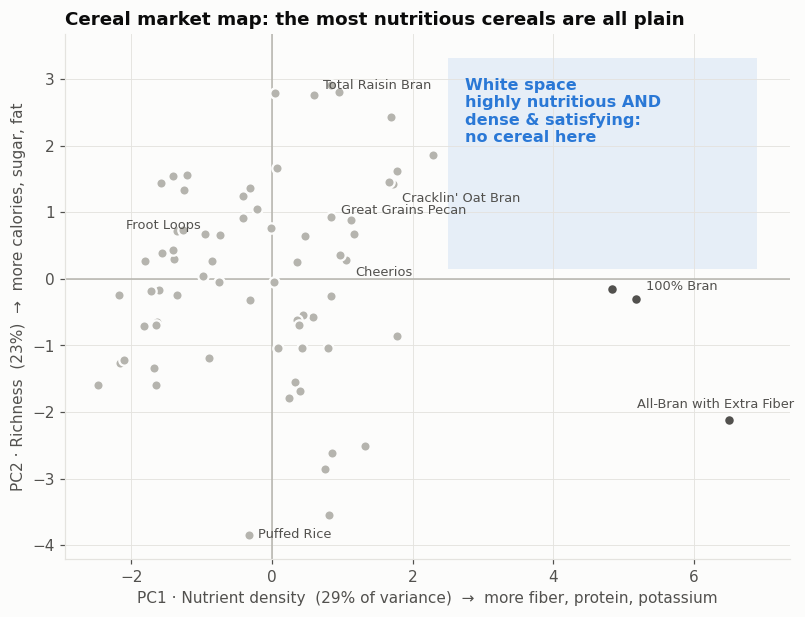

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.axhline(0, color=MUTED, lw=1); ax.axvline(0, color=MUTED, lw=1)

# The empty region: bran-level nutrition AND above-average richness
x0, x1 = GAP_X, cereal.PC1.max() + 0.4
y0, y1 = 0.15, cereal.PC2.max() + 0.4
ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, color=SERIES[0], alpha=0.10, lw=0, zorder=0))
ax.text(x0 + 0.25, y1 - 0.3, "White space\nhighly nutritious AND\ndense & satisfying:\nno cereal here",
        color=SERIES[0], fontsize=10.5, fontweight="bold", va="top")

ax.scatter(cereal.PC1, cereal.PC2, s=46, color=MUTED, edgecolor=SURFACE, lw=1.5, zorder=2)
ax.scatter(dense.PC1, dense.PC2, s=50, color=INK2, edgecolor=SURFACE, lw=1.5, zorder=3)

# Label a few reference brands only (selective, not every point)
for name, dx, dy in [("All-Bran with Extra Fiber", -60, 8), ("100% Bran", 6, 6), ("Cracklin' Oat Bran", 6, -12),
                     ("Great Grains Pecan", 6, 2), ("Froot Loops", -62, 4), ("Puffed Rice", 6, -2),
                     ("Cheerios", 6, -10), ("Total Raisin Bran", 6, 4)]:
    r = cereal[cereal.name == name]
    if len(r):
        ax.annotate(name, (r.PC1.iloc[0], r.PC2.iloc[0]), xytext=(dx, dy), textcoords="offset points",
                    fontsize=8.5, color=INK2)

ax.set_xlabel(f"PC1 · Nutrient density  ({evr[0]:.0%} of variance)  →  more fiber, protein, potassium")
ax.set_ylabel(f"PC2 · Richness  ({evr[1]:.0%})  →  more calories, sugar, fat")
ax.set_title("Cereal market map: the most nutritious cereals are all plain")
fig.savefig(FIG + "market_map.png"); plt.show()

**The gap.** Most cereals sit within ±2 of the center. The very high-nutrition cereals (the bran products on the right) are all *plain*: low in calories and fat. The *richer* cereals (raisin brans, granolas, oat clusters) only reach moderate nutrition. **No product combines bran-level nutrition with a dense, satisfying eat.** That empty upper-right corner is the launch opportunity.

**Robustness check: serving sizes differ.** Nutrition facts are *per serving*, and serving weights range from 0.5 to 1.5 oz. Re-running PCA on per-ounce values tests whether the map is just a serving-size artefact.

In [7]:
per_oz = cereal[NUTRIENTS].div(cereal["weight"], axis=0)
pca_oz = PCA(random_state=SEED).fit(StandardScaler().fit_transform(per_oz))
print(f"Per-ounce PCA: first two components explain {pca_oz.explained_variance_ratio_[:2].sum():.1%} "
      f"(vs {evr[:2].sum():.1%} per serving)")
pd.DataFrame(pca_oz.components_[:2].T, index=NUTRIENTS, columns=["PC1 per oz", "PC2 per oz"]).round(2)

Per-ounce PCA: first two components explain 56.9% (vs 52.2% per serving)


,PC1 per oz,PC2 per oz
calories,-0.42,-0.22
protein,0.35,0.11
fat,-0.02,-0.48
sodium,-0.15,0.13
fiber,0.54,-0.04
carbo,-0.23,0.58
sugars,-0.21,-0.57
potass,0.53,-0.13
vitamins,-0.11,0.12


## Part 2 · Consumer segmentation (K-means)

**Data:** 800 responses to a cereal attitudes survey: 8 demographic questions and 20 Likert-scale attitude statements (1 = strongly disagree, 5 = strongly agree). The survey was provided for the course and is not published here; see `data/README.md`.

In [8]:
QUESTIONS = {
    "Q1": "Read nutrition labels", "Q2": "Buy family size on sale", "Q3": "Choose by sweet taste",
    "Q4": "Go-to when rushing", "Q5": "Fiber & whole grain matter most", "Q6": "Whole family must agree",
    "Q7": "Late-night snack / dessert", "Q8": "Avoid dyes & HFCS", "Q9": "Eat dry on the go",
    "Q10": "Stick to classic brands", "Q11": "Love fun flavors", "Q12": "Buy for zero prep",
    "Q13": "Prefer fortified (protein/vitamins)", "Q14": "Price per ounce is key", "Q15": "Cereal = comfort treat",
    "Q16": "Keep sugar low", "Q17": "Stays crunchy at my desk", "Q18": "Buy store brand if cheaper",
    "Q19": "Like sweet leftover milk", "Q20": "Easy-reseal packaging",
}

# Note: pandas reads the text "None" as missing by default, which would wrongly
# blank out 977 valid answers ("no children", "no dietary restriction").
survey = pd.read_csv("data/consumer_survey.csv", keep_default_na=False)
print(survey.shape, "| missing values:", (survey == "").sum().sum())

# Three slightly different labels describe the same group
survey["Work_Arrangement"] = survey["Work_Arrangement"].replace(
    {"Student/Not Employed": "Not employed", "Retired/Not Employed": "Not employed", "Not Employed": "Not employed"})
survey["Work_Arrangement"].value_counts()

(800, 29) | missing values: 0


Work_Arrangement
Office          301
Hybrid          238
Remote          180
Not employed     81
Name: count, dtype: int64

Before clustering, the correlation matrix shows how the attitude statements group together. Ordering the questions by theme reveals four clear blocks.

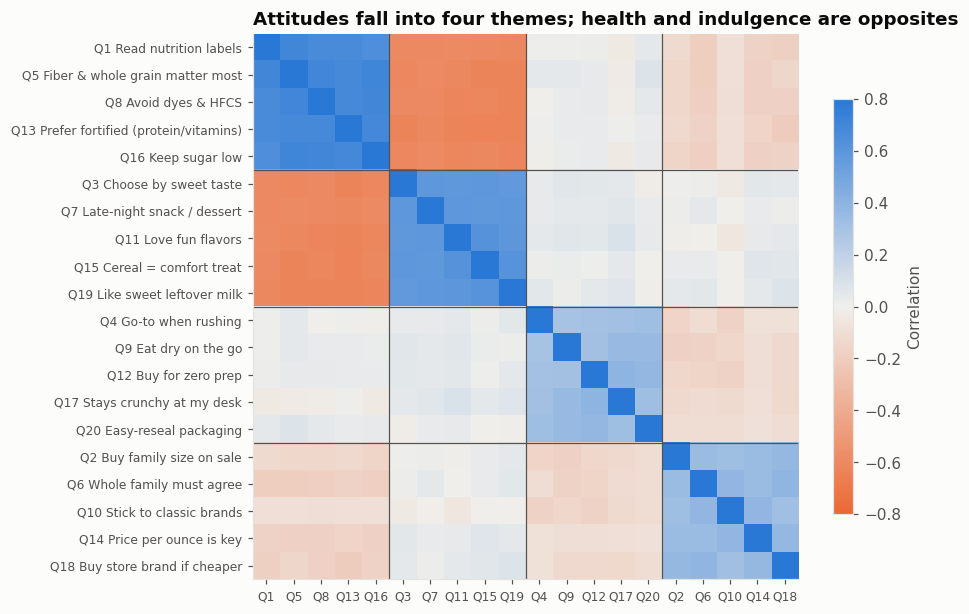

In [9]:
THEMES = {
    "Health":      ["Q1", "Q5", "Q8", "Q13", "Q16"],
    "Indulgence":  ["Q3", "Q7", "Q11", "Q15", "Q19"],
    "Convenience": ["Q4", "Q9", "Q12", "Q17", "Q20"],
    "Value & family": ["Q2", "Q6", "Q10", "Q14", "Q18"],
}
order = sum(THEMES.values(), [])
corr = survey[order].corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-0.8, vmax=0.8)
labels = [f"{q} {QUESTIONS[q]}" for q in order]
ax.set_xticks(range(20), order, fontsize=8); ax.set_yticks(range(20), labels, fontsize=8)
ax.grid(False)
for b in [4.5, 9.5, 14.5]:
    ax.axhline(b, color=INK2, lw=0.8); ax.axvline(b, color=INK2, lw=0.8)
fig.colorbar(im, ax=ax, shrink=0.7, label="Correlation")
ax.set_title("Attitudes fall into four themes; health and indulgence are opposites")
fig.savefig(FIG + "survey_correlations.png"); plt.show()

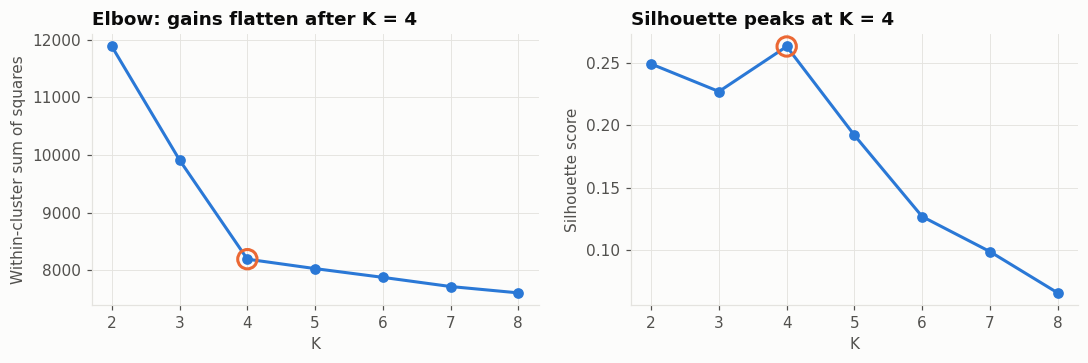

,inertia,silhouette
K,,
2,11882.028,0.249
3,9912.535,0.227
4,8196.127,0.263
5,8032.625,0.192
6,7880.961,0.127
7,7722.072,0.099
8,7612.191,0.066


In [10]:
Q = list(QUESTIONS)
X_survey = StandardScaler().fit_transform(survey[Q])

ks = range(2, 9)
fits = {k: KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_survey) for k in ks}
k_table = pd.DataFrame({
    "inertia": [fits[k].inertia_ for k in ks],
    "silhouette": [silhouette_score(X_survey, fits[k].labels_) for k in ks],
}, index=pd.Index(ks, name="K")).round(3)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(list(ks), k_table.inertia, color=SERIES[0], lw=2, marker="o", ms=6)
axes[0].set_title("Elbow: gains flatten after K = 4"); axes[0].set_xlabel("K"); axes[0].set_ylabel("Within-cluster sum of squares")
axes[1].plot(list(ks), k_table.silhouette, color=SERIES[0], lw=2, marker="o", ms=6)
axes[1].set_title("Silhouette peaks at K = 4"); axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette score")
for ax, col in zip(axes, ["inertia", "silhouette"]):
    ax.scatter([4], [k_table.loc[4, col]], s=160, facecolor="none", edgecolor=SERIES[1], lw=2, zorder=5)
fig.tight_layout(); fig.savefig(FIG + "choosing_k.png"); plt.show()
k_table

In [11]:
# Stability: does K = 4 find the same segments from different random starts?
runs = [KMeans(n_clusters=4, n_init=10, random_state=s).fit(X_survey).labels_ for s in range(20)]
ari = [adjusted_rand_score(runs[0], r) for r in runs[1:]]
print(f"Adjusted Rand index across 20 random starts: min {min(ari):.3f}, mean {np.mean(ari):.3f}")

Adjusted Rand index across 20 random starts: min 1.000, mean 1.000


**Choosing K.** The original RapidMiner assignment tested K = 3 to 6 and kept **3 segments** for interpretability. In this rebuild, both the elbow and the silhouette score point to **K = 4**, and the 4-segment solution is identical from all 20 random starts. The cells below show what the extra segment adds.

In [12]:
km = fits[4]
survey["segment_id"] = km.labels_

# Name each segment by the attitude theme it scores highest on (relative to the sample)
z = pd.DataFrame(X_survey, columns=Q).groupby(km.labels_).mean()
theme_z = pd.DataFrame({t: z[qs].mean(axis=1) for t, qs in THEMES.items()})
NAMES = {"Health": "Health Maximizers", "Indulgence": "Indulgence Seekers",
         "Convenience": "On-the-Go Convenience", "Value & family": "Family Value Shoppers"}
seg_name = theme_z.idxmax(axis=1).map(NAMES)
SEG_ORDER = list(NAMES.values())
survey["segment"] = pd.Categorical(survey["segment_id"].map(seg_name), SEG_ORDER, ordered=True)
theme_z.index = theme_z.index.map(seg_name)
theme_z = theme_z.loc[SEG_ORDER]

sizes = survey["segment"].value_counts().reindex(SEG_ORDER)
pd.DataFrame({"respondents": sizes, "share": (sizes / len(survey)).map("{:.0%}".format)})

,respondents,share
segment,,
Health Maximizers,210,26%
Indulgence Seekers,150,19%
On-the-Go Convenience,200,25%
Family Value Shoppers,240,30%


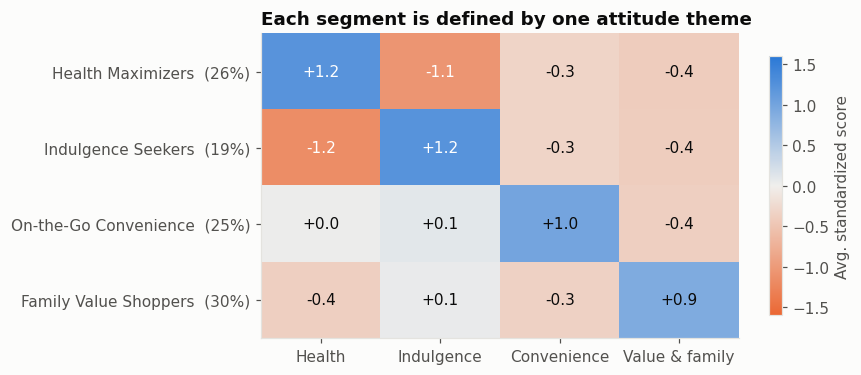

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(theme_z.values, cmap=DIVERGING, vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(4), theme_z.columns); ax.set_yticks(range(4), [f"{s}  ({sizes[s]/len(survey):.0%})" for s in SEG_ORDER])
ax.grid(False)
for (i, j), v in np.ndenumerate(theme_z.values):
    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=10, color=INK if abs(v) < 1 else "white")
fig.colorbar(im, ax=ax, shrink=0.85, label="Avg. standardized score")
ax.set_title("Each segment is defined by one attitude theme")
fig.savefig(FIG + "segment_profiles.png"); plt.show()

In [14]:
# How do the 4 segments relate to the original 3-segment answer?
k3 = pd.Series(fits[3].labels_, name="K = 3 cluster")
pd.crosstab(survey["segment"], k3)

K = 3 cluster,0,1,2
segment,,,
Health Maximizers,210,0,0
Indulgence Seekers,0,150,0
On-the-Go Convenience,0,0,200
Family Value Shoppers,0,237,3


With K = 3, *Indulgence Seekers* and *Family Value Shoppers* merge into one large group of 387 respondents (48%), the same size as the original's *Mainstream Pragmatists*. Splitting them matters for marketing: one is young, single and buys for taste, while the other is a parent buying on price and familiar brands. They need different products and messages. **Health Maximizers come out at the same size (26%) in both solutions**, so the original target holds.

In [15]:
# Who is in each segment?
def pct_table(col):
    return pd.crosstab(survey[col], survey["segment"], normalize="columns").mul(100).round(0)

profile = pd.DataFrame({
    "Avg. age": survey.groupby("segment", observed=True)["Age"].mean().round(0),
    "Income $100k+ (%)": survey.assign(x=survey.Income.isin(["$100k-$149k", "$150k+"])).groupby("segment", observed=True).x.mean().mul(100).round(0),
    "Kids at home (%)": survey.assign(x=survey.Children_at_Home != "None").groupby("segment", observed=True).x.mean().mul(100).round(0),
    "Dietary restriction (%)": survey.assign(x=survey.Dietary_Restriction != "None").groupby("segment", observed=True).x.mean().mul(100).round(0),
    "Office-based (%)": survey.assign(x=survey.Work_Arrangement == "Office").groupby("segment", observed=True).x.mean().mul(100).round(0),
    "Primary shopper (%)": survey.assign(x=survey.Primary_Shopper == "Yes").groupby("segment", observed=True).x.mean().mul(100).round(0),
}).T
profile

segment,Health Maximizers,Indulgence Seekers,On-the-Go Convenience,Family Value Shoppers
Avg. age,45.0,25.0,31.0,38.0
Income $100k+ (%),63.0,17.0,29.0,16.0
Kids at home (%),43.0,19.0,34.0,100.0
Dietary restriction (%),68.0,22.0,0.0,9.0
Office-based (%),18.0,27.0,63.0,40.0
Primary shopper (%),71.0,49.0,53.0,77.0


In [16]:
# Are the demographic differences real? Chi-square test of independence for each variable
DEMOS = ["Gender", "Income", "Marital_Status", "Children_at_Home", "Primary_Shopper", "Work_Arrangement", "Dietary_Restriction"]
tests = []
for col in DEMOS:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(survey[col], survey["segment"]))
    tests.append({"variable": col, "chi2": round(chi2, 1), "p_value": p, "significant (p<0.05)": p < 0.05})
pd.DataFrame(tests).sort_values("p_value").style.format({"p_value": "{:.1e}"})

,variable,chi2,p_value,significant (p<0.05)
6,Dietary_Restriction,507.800000,4.9e-101,True
3,Children_at_Home,435.000000,1.4e-85,True
1,Income,194.800000,4.0e-37,True
2,Marital_Status,167.600000,1.5e-33,True
5,Work_Arrangement,134.300000,1.5e-24,True
4,Primary_Shopper,72.500000,1.2e-13,True
0,Gender,4.600000,6.0e-01,False


In [17]:
pct_table("Dietary_Restriction")

segment,Health Maximizers,Indulgence Seekers,On-the-Go Convenience,Family Value Shoppers
Dietary_Restriction,,,,
Dairy-free / Vegan,9.0,10.0,0.0,0.0
Gluten-free,22.0,0.0,0.0,0.0
Low-sugar / Keto,37.0,0.0,0.0,0.0
None,32.0,78.0,100.0,91.0
Nut allergy,0.0,12.0,0.0,9.0


**Segment portraits**

| Segment | Size | Who they are | What they want |
|---|---|---|---|
| **Health Maximizers** | 26% | Oldest (avg. 45), highest income (63% earn $100k+), 68% have a dietary restriction (mostly low-sugar or gluten-free) | Fiber, protein, low sugar, clean labels |
| **Indulgence Seekers** | 19% | Youngest (avg. 25), lower income, about 1 in 5 are students, few have kids | Sweet, fun flavors; cereal as a snack or dessert |
| **On-the-Go Convenience** | 25% | Avg. age 31, 63% commute to an office | Zero prep, eat dry, stays crunchy, resealable bag |
| **Family Value Shoppers** | 30% | All have kids at home; 77% are the main grocery shopper | Price per ounce, family size, store brands, familiar names |

Gender is the only demographic that does not differ by segment.

### A short "typing tool" to find segments in the field

A 20-question survey is too long for a store intercept or a sign-up form. Can a handful of questions place a new customer in the right segment?

In [18]:
# Pick the single most discriminating question from each theme (largest spread of segment means)
spread = survey.groupby("segment", observed=True)[Q].mean().agg(lambda s: s.max() - s.min())
short_q = [spread[qs].idxmax() for qs in THEMES.values()]
print("Short form:", {q: QUESTIONS[q] for q in short_q})

clf = LogisticRegression(max_iter=1000)
acc_short = cross_val_score(clf, survey[short_q], survey["segment"].astype(str), cv=5).mean()
acc_full = cross_val_score(clf, survey[Q], survey["segment"].astype(str), cv=5).mean()
print(f"5-fold accuracy: 4 questions {acc_short:.1%} | all 20 questions {acc_full:.1%}")

Short form: {'Q5': 'Fiber & whole grain matter most', 'Q11': 'Love fun flavors', 'Q12': 'Buy for zero prep', 'Q10': 'Stick to classic brands'}


5-fold accuracy: 4 questions 87.3% | all 20 questions 99.8%


## Part 3 · Recommendation

**Launch a high-protein, high-fiber, low-sugar cereal with a dense, crunchy texture (working name *PowerCrunch Protein Clusters*), targeted at Health Maximizers.**

**Why this product, for this segment**
- **The market gap.** On the PCA map, no cereal combines bran-level nutrition with a rich, satisfying eat. The most nutritious products are all plain, and the rich ones are only moderately nutritious.
- **The customer who wants it.** Health Maximizers score highest on every health statement: reading labels, fiber and whole grain, fortification, low sugar, and avoiding dyes and HFCS.
- **Big enough, and worth it.** The segment is 26% of respondents, has the highest household incomes in the sample (63% earn $100k+), and 71% do the household's grocery shopping.
- **Product requirements from the data.** 37% of the segment is low-sugar or keto and 22% is gluten-free. Both should be designed in from day one, not added later.

**Secondary opportunity.** On-the-Go Convenience (25%) wants cereal that stays crunchy, travels dry, and comes in resealable packs. A single-serve snack pouch of the same clusters could reach them later without a new formula.

**How to reach Health Maximizers.** Lead with the nutrition panel (protein and fiber grams, no artificial dyes) rather than taste. Use the 4-question typing tool to tag them in loyalty sign-ups or sampling events.

## Limitations
- The survey data comes from a course exercise, and its clusters are cleaner than real-world survey data usually is. On real data, expect lower silhouette scores and more overlap between segments.
- The nutrition dataset covers 74 US cereals and is not current. The map shows the method; a real launch would refresh it with today's shelf.
- Likert responses are treated as interval data for K-means, which is standard practice but an assumption.
- Segment sizes are shares of respondents, not of the US market. Sizing in dollars would need weighting to census and purchase data.